<a href="https://colab.research.google.com/github/Abdoulaye279/Quantum-Computing/blob/main/04_bus_and_molmer_sorensen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 - Warm bus, and the Molmer-Sorensen gate

The Cirac-Zoller gate needs the bus in n=0 (blue sideband Rabi frequency goes as sqrt(n+1)). Compared with a Molmer-Sorensen gate: two tones detuned by +-delta, H = g (sx1 + sx2)(a e^{i delta t} + h.c.), bus back to its initial state after T = 2pi/delta.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Quantum-Computing
    %cd Quantum-Computing
except ImportError:
    pass

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cirac_zoller import *
plt.style.use("quant.mplstyle")

labels = ["SS", "SD", "DS", "DD"]

In [3]:
Ucz = gate_amp(0.0)
for n0 in range(4):
    print(f"bus in n={n0}: Bell fidelity {bell_fidelity(bell_rho(Ucz, n0)):.3f}")
# one phonon already costs 5%, two phonons and the gate is broken (0.33)

bus in n=0: Bell fidelity 1.000
bus in n=1: Bell fidelity 0.952
bus in n=2: Bell fidelity 0.331
bus in n=3: Bell fidelity 0.321


MS vs ideal XX gate: 1.0
Bell fidelity from |SS>: 1.0


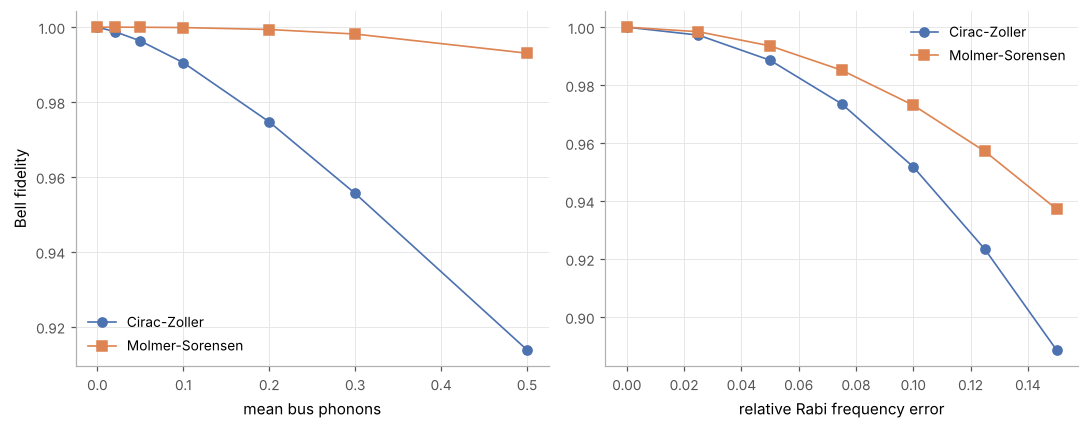

n=0.5: CZ 0.914  MS 0.993


In [4]:
delta = 2 * np.pi / 300.0
g0 = delta / 4
Ums = ms_gate(g0)
print("MS vs ideal XX gate:", round(abs(np.trace(ms_ideal().conj().T @ eff_unitary(Ums))) ** 2 / 16, 4))
print("Bell fidelity from |SS>:", round(bell_fidelity(ms_bell_rho(Ums)), 4))

nbars = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
Fcz = [sum(thermal_weights(nb)[n] * bell_fidelity(bell_rho(Ucz, n)) for n in range(6)) for nb in nbars]
Fms = [sum(thermal_weights(nb)[n] * bell_fidelity(ms_bell_rho(Ums, n)) for n in range(6)) for nb in nbars]
eps = np.linspace(0, 0.15, 7)
Fcz_a = [bell_fidelity(bell_rho(gate_amp(x))) for x in eps]
Fms_a = [bell_fidelity(ms_bell_rho(ms_gate(g0 * (1 + x)))) for x in eps]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(nbars, Fcz, "o-", label="Cirac-Zoller"); ax[0].plot(nbars, Fms, "s-", label="Molmer-Sorensen")
ax[0].set_xlabel("mean bus phonons"); ax[0].set_ylabel("Bell fidelity"); ax[0].legend()
ax[1].plot(eps, Fcz_a, "o-", label="Cirac-Zoller"); ax[1].plot(eps, Fms_a, "s-", label="Molmer-Sorensen")
ax[1].set_xlabel("relative Rabi frequency error"); ax[1].legend()
plt.tight_layout(); plt.show()
print("n=0.5: CZ", round(Fcz[-1], 3), " MS", round(Fms[-1], 3))
# CZ drops fast once the bus is a bit warm -> needs sideband cooling (~99% in n=0 in the paper)
# MS barely moves with temperature (at first order in Lamb-Dicke), which is why most recent experiments use it
# the small drop left for MS comes from the time steps and the truncated phonon space